In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import RidgeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

aqs = pd.read_csv('C:/Users/mayav/Desktop/GEOL415/LA_AQS_2023.csv')
O3_aqs = aqs[(aqs['Parameter Name']=='Ozone')]
NO2_aqs = aqs[(aqs['Parameter Name']=='Nitrogen dioxide (NO2)')]
PM_aqs = aqs[(aqs['Parameter Name']=='PM2.5 - Local Conditions')]

O3 = pd.DataFrame(data = {"O3" : (O3_aqs['Arithmetic Mean']* 1e3), 'Time' : (O3_aqs['Date (Local)'])})
NO2 = pd.DataFrame(data = {"NO2" : (NO2_aqs['Arithmetic Mean']), 'Time' : (NO2_aqs['Date (Local)'])})
PM = pd.DataFrame(data = {"PM" : (PM_aqs['Arithmetic Mean']), 'Time' : (PM_aqs['Date (Local)'])})

df = O3.merge(NO2, on=['Time']).merge(PM, on=['Time'])


In [2]:
# Using the EPA AQS data make a scatter plot of O3 vs NO2 concentrations and O3 vs PM2.5 concentrations.

<Axes: >

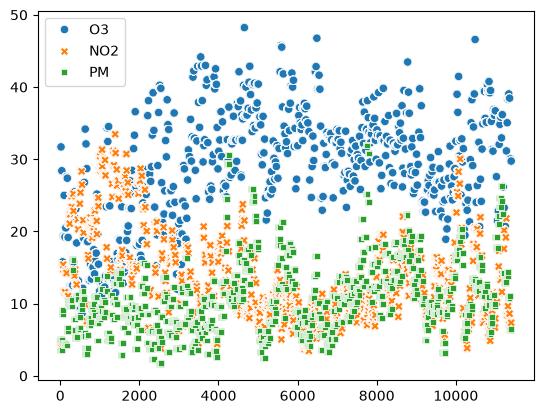

In [3]:
sns.scatterplot(data=(df))

<Axes: xlabel='NO2', ylabel='O3'>

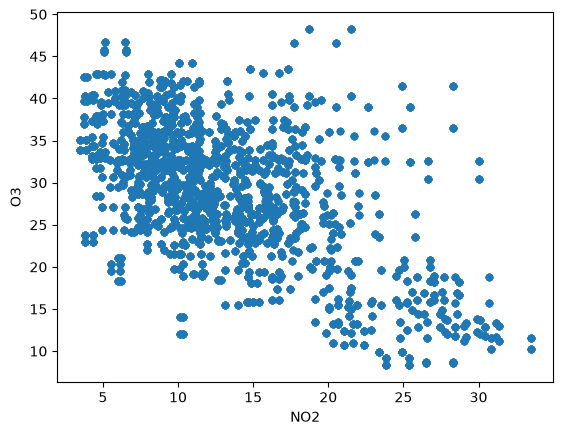

In [4]:
df.plot.scatter('NO2', 'O3')

<Axes: xlabel='PM', ylabel='O3'>

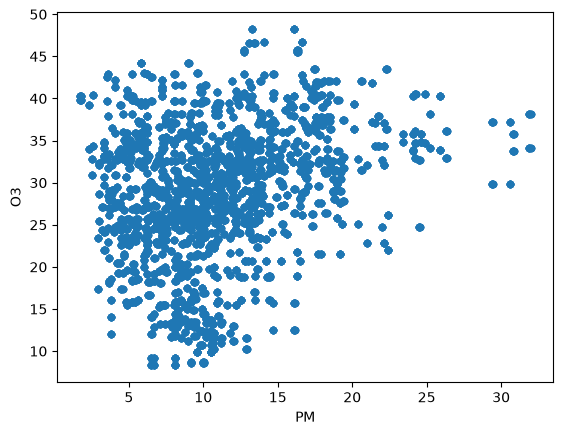

In [5]:
df.plot.scatter('PM', 'O3')

In [6]:
df.head()

,O3,Time,NO2,PM
0,31.708,2023-01-01,4.816667,3.6000
1,31.708,2023-01-01,4.816667,3.6000
2,31.708,2023-01-01,4.816667,5.0875
3,31.708,2023-01-01,4.816667,5.0000
4,31.708,2023-01-01,4.816667,5.0000


In [7]:
# summer ( 20th june to 21th sept ) winter (20th dec- 20th march--> alter to 1 jan because data only goes until september) 
# train on y/n parameter for summer, y/n parameter for winter, y/n parameter for other?

In [8]:
summerlowerbound = df[df['Time'] > '2023-06-20' ]
summerupperbound = df[df['Time'] < '2023-09-21']

summerdf = summerlowerbound.merge(summerupperbound)

winterlowerbound = df[df['Time'] > '2023-01-01' ]
winterupperbound = df[df['Time'] < '2023-03-21']

winterdf = winterlowerbound.merge(winterupperbound)

In [10]:
# call it pop for ease of typing...

In [11]:
pop = pd.concat([winterdf, summerdf])

In [12]:
pop['Winter Y/N'] = np.where(pop['Time'] < '2023-03-22', 1, 0)

In [13]:
# if value belongs to summer set -> 1 for true

In [14]:
yesno = pop['Winter Y/N']    
yesno.to_numpy()

conc = pd.DataFrame(data = {"O3" : pop['O3'], "NO2" : pop['NO2'], "PM" : pop['PM']})
conc.to_numpy()

array([[15.792   , 14.720833,  8.6     ],
       [15.792   , 14.720833,  8.6     ],
       [15.792   , 14.720833,  8.6     ],
       ...,
       [36.706   ,  7.958333, 10.      ],
       [36.706   ,  7.958333, 10.      ],
       [36.706   ,  7.958333, 10.      ]], shape=(26592, 3))

In [15]:
# split data

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(conc, yesno, test_size=0.2)

In [17]:
Ridge1 = RidgeClassifier(alpha=1).fit(X_train,y_train) 
Ridge1.score(X_train,y_train) 

0.8273398204296526

In [18]:
Ridge1.score(X_test,y_test) 

0.8242150780221846

In [19]:
Ridge2 = RidgeClassifier(alpha=0).fit(X_train,y_train) 
Ridge2.score(X_train,y_train) 

0.8273398204296526

In [20]:
Ridge2.score(X_test,y_test) 

0.8242150780221846

In [21]:
c = RidgeClassifier(alpha=727).fit(X_train,y_train) 
c.score(X_train,y_train) 

0.827527852207023

In [22]:
c.score(X_test,y_test)

0.8242150780221846

In [23]:
d = RidgeClassifier(alpha=448).fit(X_train,y_train) 
d.score(X_train,y_train) 

0.827527852207023

In [24]:
d.score(X_test,y_test)

0.8242150780221846

In [25]:
# compare to log model

In [26]:
Log1 = LogisticRegression().fit(X_train,y_train) 
Log1.score(X_test,y_test)

0.8373754465125024

In [27]:
Log1.score(X_train,y_train) 

0.8421003149532271

In [28]:
# .predict would predict